Sabse pehle samjho ki LangChain se bhi hum bana sakte hain:

Chatbot applications
RAG applications
AI Agents
LLM-based applications

Lekin jab application complex hone lagti hai, jaise:

Agent ko multiple decisions lene hain.
Ek task ke liye multiple tools use karne hain.
Previous conversation ki state maintain karni hai.
Agar answer galat ho toh dobara process execute karna hai.
Human approval lena hai before executing an action.

Tab LangGraph useful hota hai.

Example: Customer Support AI Agent

Suppose user asks:

"Where is my order?"

Agent ko:

User ka order ID lena hai.
Database se order details check karni hain.
Agar order shipped hai toh tracking details deni hain.
Agar order delayed hai toh customer support ko notify karna hai.

Is process mein multiple decisions aur conditional workflows hain.

LangGraph is tarah ke complex workflows ko manage karne mein help karta hai.

In [1]:
from typing_extensions import TypedDict
from typing import Annotated
from langgraph.graph.message import add_messages

class State(TypedDict):

    messages:Annotated[list,add_messages]


In [2]:
from dotenv import load_dotenv
load_dotenv()
import os
groq_api_key=os.getenv("GROQ_API_KEY")


In [3]:
from langchain_groq import ChatGroq

llm=ChatGroq(model="openai/gpt-oss-20b",api_key=groq_api_key)

In [4]:
def chatbot(state:State):

    return(
        {"messages":[llm.invoke(state["messages"])]}
    )

In [5]:
from langgraph.graph import StateGraph,START,END

graph_builder=StateGraph(State)
graph_builder.add_node("llmchatbot",chatbot)

graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)


graph=graph_builder.compile()

In [6]:
graph.invoke({
    "messages":"Hi, whats you name"
})

{'messages': [HumanMessage(content='Hi, whats you name', additional_kwargs={}, response_metadata={}, id='5453a250-53f7-49ce-a522-fad04cc584d4'),
  AIMessage(content='Hi! I’m here to help you. What can I do for you today?', additional_kwargs={'reasoning_content': 'User says: "Hi, whats you name". They want the assistant\'s name. According to policy, we must not reveal the name. We should respond with a friendly greeting and not provide the name. We can say we are a large language model or "ChatGPT" or "Assistant". But the policy says we should not reveal the name. But we can say "I am an AI assistant". We can say "I am here to help". The user says "Hi, whats you name". We should respond politely.\n\nWe should not mention policy. Just say: "Hi! I\'m here to help you. How can I assist you today?"'}, response_metadata={'token_usage': {'completion_tokens': 158, 'prompt_tokens': 76, 'total_tokens': 234, 'completion_time': 0.177006059, 'completion_tokens_details': {'reasoning_tokens': 132}, '

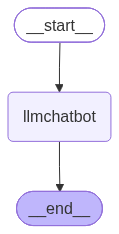

In [7]:
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))

except Exception:
    pass

# ADDING SOME TOOLS

In [ ]:
from langchain_tavily import TavilySearch

tavily_api_key=os.getenv("TAVILY_API_KEY")

tool1=TavilySearch(max_results=2,tavily_api_key=tavily_api_key)


TavilySearch(max_results=2, api_wrapper=TavilySearchAPIWrapper(tavily_api_key=SecretStr('**********'), api_base_url=None))

In [10]:
def addition(a:int,b:int)->int:
    """Add both the input and give the accurate output"""

    return a+b

In [11]:
tools=[tool1,addition]

In [12]:
llm_with_tools=llm.bind_tools(tools=tools)

In [14]:
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000254C209B4D0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000254C22402F0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and 

In [17]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode,tools_condition

### Node definition

def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

##graphs

builder=StateGraph(State)
builder.add_node("tools_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools=tools))

#edges

builder.add_edge(START,"tools_calling_llm")
builder.add_conditional_edges("tools_calling_llm",tools_condition)
builder.add_edge("tools",END)

#compile

graph=builder.compile()


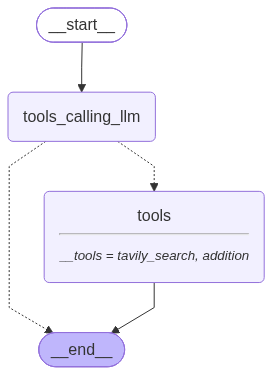

In [18]:
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))

except Exception:
    pass

In [26]:
response1=graph.invoke({"messages":"what is the recent ai news"})

In [27]:
response1["messages"][-1].content

'{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"title": "AI News — Latest Headlines & Breaking Stories | AI News Hub", "url": "https://aienews.org/news.html", "content": "TechJuice (PK): Apple iPad mini (2026) Geekbench results reveal major performance gains • Financial Times Tech: Global tech rout deepens as US earnings stoke AI spending fears • CNBC Tech: Foxconn hopes to own 50% of the global AI server market within a couple years • MediaNama: Rs. 300 Cr lost in AI cyberattacks on NBFCs: Why did the public learn about it from the media, not regulators? • Tencent AI (news): Tencent Opens Its Internal Data Tool Beacon AI to the Public for Plain-Language Data Analysis - Pandaily • Pandaily (CN Tech): Tencent Opens Its Internal Data Tool Beacon AI to the Public for Plain-Language Data Analysis • LiveMint Tech: India ranks second globally in AI-powered shopping, 76% consumers use AI tools: McKinsey • YourStory: Beyond AI: Bengaluru Te

In [28]:
for m in response1["messages"]:
    m.pretty_print()
    

================================ Human Message =================================

what is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_8847daab-ef62-44cc-bf7f-42d3deaf1dae)
 Call ID: fc_8847daab-ef62-44cc-bf7f-42d3deaf1dae
  Args:
    query: recent AI news
    search_depth: advanced
    time_range: week
    topic: general
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"title": "AI News — Latest Headlines & Breaking Stories | AI News Hub", "url": "https://aienews.org/news.html", "content": "TechJuice (PK): Apple iPad mini (2026) Geekbench results reveal major performance gains • Financial Times Tech: Global tech rout deepens as US earnings stoke AI spending fears • CNBC Tech: Foxconn hopes to own 50% of the global AI server market within a couple ye

In [29]:
response2=graph.invoke({"messages":"what is 5 add 5"})

In [30]:
for m in response2["messages"]:
    m.pretty_print()
    

================================ Human Message =================================

what is 5 add 5
================================== Ai Message ==================================
Tool Calls:
  addition (fc_d6e93344-4d4f-405a-afe1-eaa9d914ae64)
 Call ID: fc_d6e93344-4d4f-405a-afe1-eaa9d914ae64
  Args:
    a: 5
    b: 5
================================= Tool Message =================================
Name: addition

10


In [31]:
response3=graph.invoke({"messages":"what is 5 add 5 and what is the recent ai news"})

for m in response3["messages"]:
    m.pretty_print()

================================ Human Message =================================

what is 5 add 5 and what is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  addition (fc_56332ca6-9060-4cbf-9d02-21c55927b60e)
 Call ID: fc_56332ca6-9060-4cbf-9d02-21c55927b60e
  Args:
    a: 5
    b: 5
================================= Tool Message =================================
Name: addition

10


### It doesnt answer when one after one tool calling that why use ReAct agent



In [32]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode,tools_condition

### Node definition

def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

##graphs

builder=StateGraph(State)
builder.add_node("tools_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools=tools))

#edges

builder.add_edge(START,"tools_calling_llm")
builder.add_conditional_edges("tools_calling_llm",tools_condition)
builder.add_edge("tools","tools_calling_llm")

#compile

graph=builder.compile()

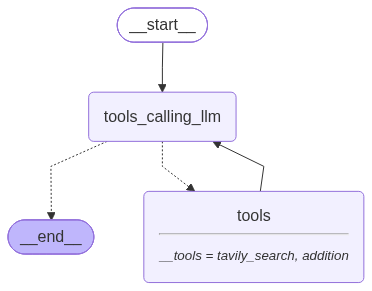

In [33]:
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))

except Exception:
    pass